<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 3: Probability Distributions and Bayes' Theorem

**Category**: CO1 – Mathematical Foundations and Optimization  
**Objective**: Model standard probability distributions and apply Bayes' theorem to medical diagnostic inference with simulation verification.


### Task 1: Probability Distribution Modeling and Density Plots


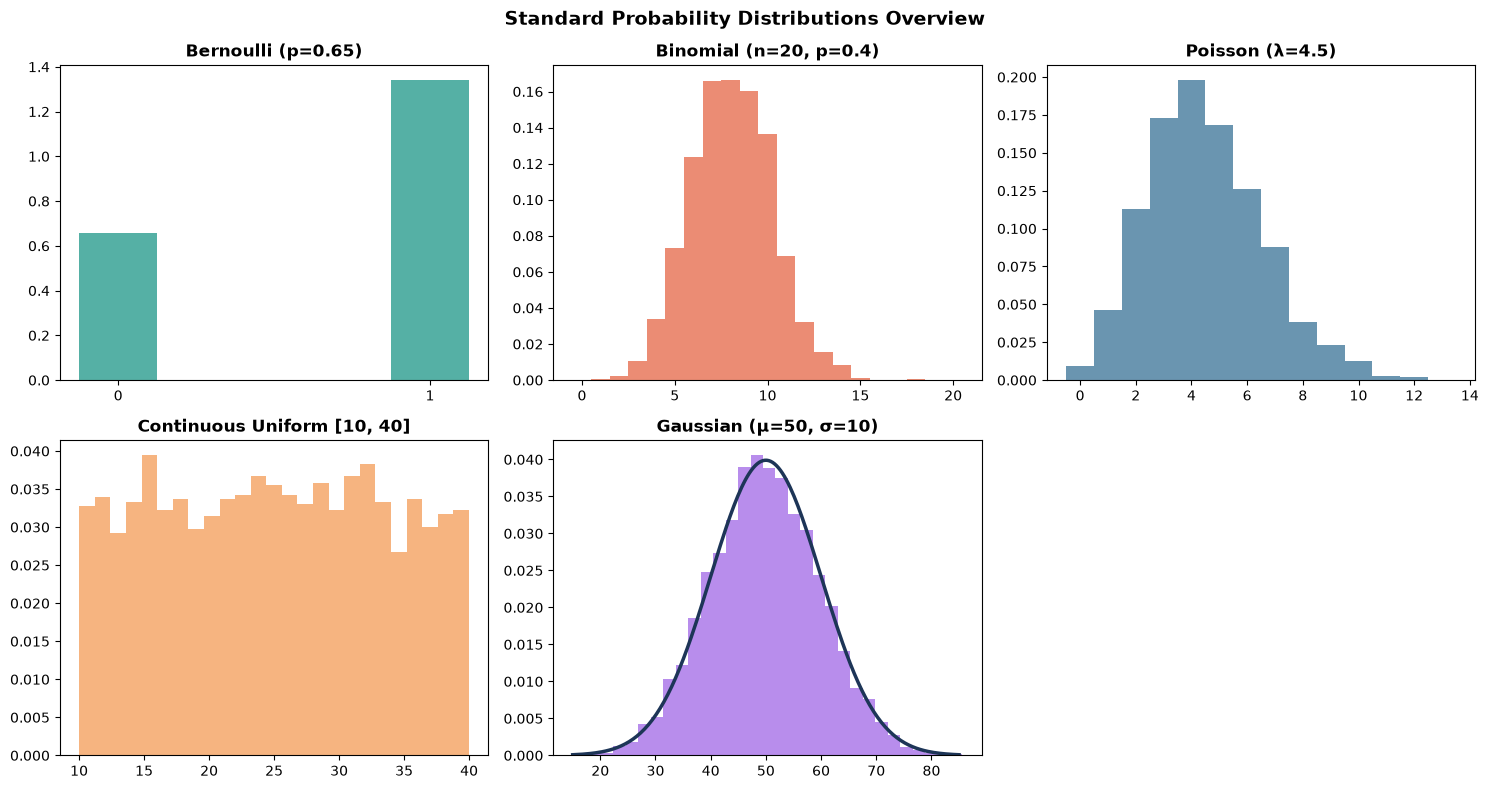

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(77)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# 1. Bernoulli
p_bern = 0.65
bern_samples = stats.bernoulli.rvs(p_bern, size=1000)
axes[0].hist(bern_samples, bins=[-0.25, 0.25, 0.75, 1.25], rwidth=0.5, density=True, color='#2a9d8f', alpha=0.8)
axes[0].set_title(f"Bernoulli (p={p_bern})", fontweight='bold')
axes[0].set_xticks([0, 1])

# 2. Binomial
n_trials, p_bi = 20, 0.4
binom_s = stats.binom.rvs(n_trials, p_bi, size=2000)
axes[1].hist(binom_s, bins=np.arange(n_trials+2)-0.5, density=True, color='#e76f51', alpha=0.8)
axes[1].set_title(f"Binomial (n={n_trials}, p={p_bi})", fontweight='bold')

# 3. Poisson
mu_poi = 4.5
poi_s = stats.poisson.rvs(mu_poi, size=2000)
axes[2].hist(poi_s, bins=np.arange(15)-0.5, density=True, color='#457b9d', alpha=0.8)
axes[2].set_title(f"Poisson (λ={mu_poi})", fontweight='bold')

# 4. Uniform
unif_s = stats.uniform.rvs(loc=10, scale=30, size=3000)
axes[3].hist(unif_s, bins=25, density=True, color='#f4a261', alpha=0.8)
axes[3].set_title("Continuous Uniform [10, 40]", fontweight='bold')

# 5. Gaussian
norm_s = stats.norm.rvs(loc=50, scale=10, size=3000)
x_span = np.linspace(15, 85, 200)
axes[4].hist(norm_s, bins=30, density=True, color='#9b5de5', alpha=0.7)
axes[4].plot(x_span, stats.norm.pdf(x_span, loc=50, scale=10), color='#1d3557', lw=2.5)
axes[4].set_title("Gaussian (μ=50, σ=10)", fontweight='bold')

axes[5].axis('off')
plt.suptitle("Standard Probability Distributions Overview", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### Task 2: Bayes' Theorem for Clinical Diagnosis


In [2]:
# Diagnostic Center Parameters
prevalence = 0.012      # P(Disease)
sensitivity = 0.94     # P(Pos | Disease)
specificity = 0.91     # P(Neg | No Disease)

# P(Positive) = P(Pos|D)*P(D) + P(Pos|~D)*P(~D)
p_pos_given_no_d = 1.0 - specificity
p_positive = (sensitivity * prevalence) + (p_pos_given_no_d * (1.0 - prevalence))

# Posterior P(Disease | Positive)
p_disease_given_pos = (sensitivity * prevalence) / p_positive

print(f"Prior Disease Prevalence: {prevalence*100:.2f}%")
print(f"Test Sensitivity: {sensitivity*100:.1f}%, Specificity: {specificity*100:.1f}%")
print(f"Overall P(Positive Test): {p_positive*100:.3f}%")
print(f"Posterior P(Disease | Positive Test): {p_disease_given_pos*100:.2f}%")


Prior Disease Prevalence: 1.20%
Test Sensitivity: 94.0%, Specificity: 91.0%
Overall P(Positive Test): 10.020%
Posterior P(Disease | Positive Test): 11.26%


### Task 3: Large-Scale Monte Carlo Verification and Prevalence Sensitivity Curve


Empirical Posterior from 150,000 Simulations: 10.96%


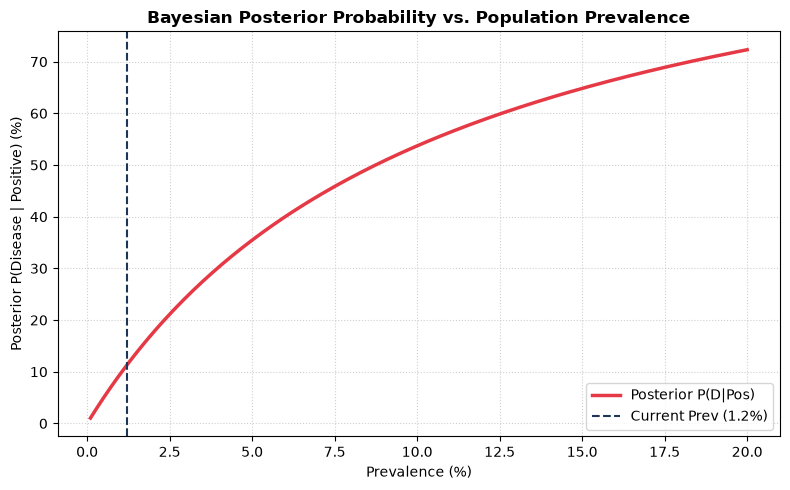

In [3]:
# 1. Empirical Monte Carlo simulation with 150,000 subjects
n_sim = 150000
has_disease = (np.random.rand(n_sim) < prevalence)
test_positive = np.zeros(n_sim, dtype=bool)

test_positive[has_disease] = (np.random.rand(np.sum(has_disease)) < sensitivity)
test_positive[~has_disease] = (np.random.rand(np.sum(~has_disease)) >= specificity)

sim_posterior = np.sum(has_disease & test_positive) / np.sum(test_positive)
print(f"Empirical Posterior from {n_sim:,} Simulations: {sim_posterior*100:.2f}%")

# 2. Posterior vs Prevalence Curve
prev_range = np.linspace(0.001, 0.20, 200)
post_curve = (sensitivity * prev_range) / ((sensitivity * prev_range) + (1.0 - specificity) * (1.0 - prev_range))

plt.figure(figsize=(8, 5))
plt.plot(prev_range * 100, post_curve * 100, color='#e63946', lw=2.5, label='Posterior P(D|Pos)')
plt.axvline(prevalence * 100, color='#1d3557', linestyle='--', label=f'Current Prev ({prevalence*100:.1f}%)')
plt.title("Bayesian Posterior Probability vs. Population Prevalence", fontweight='bold', fontsize=12)
plt.xlabel("Prevalence (%)")
plt.ylabel("Posterior P(Disease | Positive) (%)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()
